# Exploratory Data Analysis (EDA) with the Titanic Dataset

Main workflow:

1. Understand the dataset.
2. Inspect structure and data quality.
3. Handle missing values and duplicates.
4. Explore distributions and relationships.
5. Detect and handle outliers.
6. Prepare data for modeling.

## 1. Python Libraries You Need For EDA

- **NumPy** for numerical arrays and calculations.
- **Pandas** for tables, data cleaning, and data analysis.
- **Matplotlib** for charts and visualizations.



## 2. Dataset Explanation

We will use the Titanic passenger dataset.

The target column is:

- `Survived`: `1` means survived, `0` means did not survive.

Important feature columns:

| Column | Meaning |
|---|---|
| `PassengerId` | Unique passenger identifier |
| `Pclass` | Ticket class: 1st, 2nd, or 3rd |
| `Name` | Passenger name |
| `Sex` | Passenger gender |
| `Age` | Passenger age |
| `SibSp` | Number of siblings/spouses aboard |
| `Parch` | Number of parents/children aboard |
| `Ticket` | Ticket number |
| `Fare` | Ticket price |
| `Cabin` | Cabin number |
| `Embarked` | Port of embarkation |

EDA is about understanding the data before modeling.


## 3. Setup


In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


## 4. Load Data


In [ ]:
# Load the Titanic dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print("Dataset loaded successfully")


Dataset loaded successfully


In [ ]:
# Show random rows
display(df.sample(5, random_state=0))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
495,496,0,3,"Yousseff, Mr. Gerious",male,NaN,0,0,2627,14.4583,NaN,C
648,649,0,3,"Willey, Mr. Edward",male,NaN,0,0,S.O./P.P. 751,7.5500,NaN,S
278,279,0,3,"Rice, Master. Eric",male,7.0,4,1,382652,29.1250,NaN,Q
31,32,1,1,"Spencer, Mrs. William Augustus (Marie Eugenie)",female,NaN,1,0,PC 17569,146.5208,B78,C
255,256,1,3,"Touma, Mrs. Darwis (Hanne Youssef Razi)",female,29.0,0,2,2650,15.2458,NaN,C


## 5. Basic Dataset Inspection


In [59]:
# Check dataset shape
rows, columns = df.shape

print(f"Rows: {rows}")
print(f"Columns: {columns}")

Rows: 891
Columns: 12


In [61]:
# Display column names
print(df.columns.tolist())


['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [63]:
# Display data types
display(df.dtypes)


PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [64]:
# Show full dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [65]:
# Select numerical columns
numeric_columns = df.select_dtypes(include="number").columns.tolist()
print(numeric_columns)


['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']


In [67]:
# Select categorical columns
categorical_columns = df.select_dtypes(include="object").columns.tolist()
print(categorical_columns)

['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


## 6. Descriptive Statistics


In [68]:
# Describe numerical columns
display(df.describe())

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [69]:
# Count unique values in each column
display(df.nunique().sort_values())

Survived         2
Sex              2
Pclass           3
Embarked         3
SibSp            7
Parch            7
Age             88
Cabin          147
Fare           248
Ticket         681
PassengerId    891
Name           891
dtype: int64

In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [71]:
# Value counts for the target column
display(df["Survived"].value_counts(normalize=True))

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

In [72]:
# Normalized value counts for the target column
display(df["Pclass"].value_counts(normalize=True))

Pclass
3    0.551066
1    0.242424
2    0.206510
Name: proportion, dtype: float64

## 7. Missing Values


In [73]:
# Count missing values
df.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [74]:
# Calculate missing value percenta
df.isnull().mean().sort_values(ascending=False) * 100


Cabin          77.104377
Age            19.865320
Embarked        0.224467
PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
dtype: float64

In [75]:
# Show only columns with missing values
missing_summary = df.isnull().sum()
display(missing_summary[missing_summary > 0].sort_values(ascending=False))

Cabin       687
Age         177
Embarked      2
dtype: int64

## 8. Data Cleaning

Cleaning decisions:

- Drop `Cabin` because it has many missing values.
- Fill missing `Age` with the median.
- Fill missing `Embarked` with the mode.


In [76]:
# Copy the original dataset
df_cleaned = df.copy()

print("Copy created:", df_cleaned.shape)

Copy created: (891, 12)


In [77]:
# Drop Cabin column
df_cleaned = df_cleaned.drop(columns=["Cabin"])

print("Cabin column dropped")
print(df_cleaned.columns.tolist())

Cabin column dropped
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked']


In [78]:
# Fill missing Age with median
median_age = df_cleaned["Age"].median()
df_cleaned["Age"] = df_cleaned["Age"].fillna(median_age)

print("Median age:", median_age)
print("Missing Age after fill:", df_cleaned["Age"].isnull().sum())

Median age: 28.0
Missing Age after fill: 0


In [79]:
df_cleaned.isnull().sum()   

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       2
dtype: int64

In [80]:
# Fill missing Embarked with mode
mode_embarked = df_cleaned["Embarked"].mode()[0]
df_cleaned["Embarked"] = df_cleaned["Embarked"].fillna(mode_embarked)

print("Mode embarked:", mode_embarked)
print("Missing Embarked after fill:", df_cleaned["Embarked"].isnull().sum())

Mode embarked: S
Missing Embarked after fill: 0


In [81]:
# Verify missing values after cleaning
display(df_cleaned.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

## 9. Duplicate Rows


In [82]:
# Count duplicate rows
duplicate_count = df_cleaned.duplicated().sum()
print("Duplicate rows:", duplicate_count)

Duplicate rows: 0





The dataset contains no duplicate rows.
Therefore, no rows were removed during this step.


## 10. Feature Preparation After Data Cleaning

After handling missing values and duplicates, we should create the columns we need for analysis.

This must happen before charts and heatmaps so the new columns appear in the analysis.

In this section we create:

- `Sex_Encoded`
- `Embarked_Encoded`
- `FamilySize`
- `IsAlone`

We keep the original columns and add new columns, so the data remains readable and useful.


In [83]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 76.7+ KB


In [84]:
df_cleaned = df_cleaned.drop(columns=["PassengerId", "Name", "Ticket"])


In [85]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  891 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [86]:
# Convert Sex column to 0 and 1
# female = 0, male = 1

df_prep = df_cleaned.copy()
df_prep["Sex_Encoded"] = df_prep["Sex"].map({
    "female": 0,
    "male": 1
})

display(df_prep[["Sex", "Sex_Encoded"]].head(10))

,Sex,Sex_Encoded
0,male,1
1,female,0
2,female,0
3,female,0
4,male,1
5,male,1
6,male,1
7,male,1
8,female,0
9,female,0


In [87]:
# Check survival rate by encoded Sex

sex_survival = df_prep.groupby(["Sex", "Sex_Encoded"])["Survived"].mean()

display(sex_survival)

Sex     Sex_Encoded
female  0              0.742038
male    1              0.188908
Name: Survived, dtype: float64

In [88]:
# Convert Embarked column to numbers
# C = 0, Q = 1, S = 2

df_prep["Embarked_Encoded"] = df_prep["Embarked"].map({
    "C": 0,
    "Q": 1,
    "S": 2
})

display(df_prep[["Embarked", "Embarked_Encoded"]].head(10))

,Embarked,Embarked_Encoded
0,S,2
1,C,0
2,S,2
3,S,2
4,S,2
5,Q,1
6,S,2
7,S,2
8,S,2
9,C,0


In [89]:
# Check relationship between Embarked and survival

embarked_survival = df_prep.groupby(["Embarked", "Embarked_Encoded"])["Survived"].mean()

display(embarked_survival)

Embarked  Embarked_Encoded
C         0                   0.553571
Q         1                   0.389610
S         2                   0.339009
Name: Survived, dtype: float64

## 11. Feature Engineering: FamilySize and IsAlone

Feature engineering means creating new useful columns from existing columns.

Here we combine:

- `SibSp`: siblings/spouses aboard
- `Parch`: parents/children aboard

New feature:

`FamilySize = SibSp + Parch + 1`

We add `1` because the passenger themself is part of the family group.


In [90]:
# Create FamilySize feature

df_prep["FamilySize"] = df_prep["SibSp"] + df_prep["Parch"] + 1

display(df_prep[["SibSp", "Parch", "FamilySize"]].head(10))

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1
5,0,0,1
6,0,0,1
7,3,1,5
8,0,2,3
9,1,0,2


In [91]:
# Create IsAlone feature
# IsAlone = 1 means the passenger traveled alone
# IsAlone = 0 means the passenger traveled with family

df_prep["IsAlone"] = np.where(df_prep["FamilySize"] == 1, 1, 0)

display(df_prep[["SibSp", "Parch", "FamilySize", "IsAlone"]].head(10))

,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1
5,0,0,1,1
6,0,0,1,1
7,3,1,5,0
8,0,2,3,0
9,1,0,2,0


In [92]:
# Compare survival rate for alone vs not alone passengers

alone_survival = df_prep.groupby("IsAlone")["Survived"].mean()

display(alone_survival)

IsAlone
0    0.505650
1    0.303538
Name: Survived, dtype: float64

In [93]:
# Compare survival rate by family size

family_survival = df_prep.groupby("FamilySize")["Survived"].mean()

display(family_survival)

FamilySize
1     0.303538
2     0.552795
3     0.578431
4     0.724138
5     0.200000
6     0.136364
7     0.333333
8     0.000000
11    0.000000
Name: Survived, dtype: float64

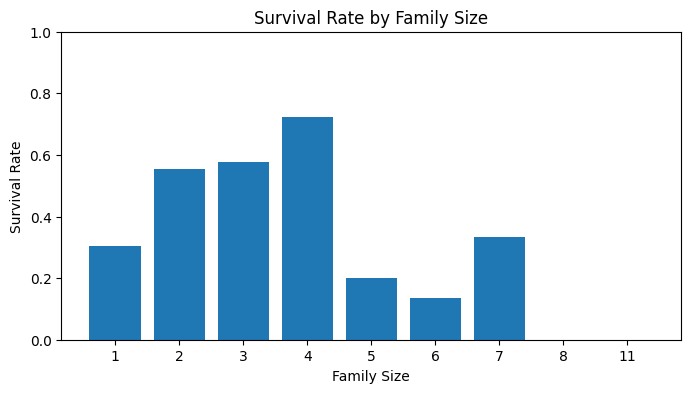

In [94]:
# Bar chart: survival rate by FamilySize

plt.figure(figsize=(8, 4))
plt.bar(family_survival.index.astype(str), family_survival.values)
plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.show()

## 12. Univariate Analysis


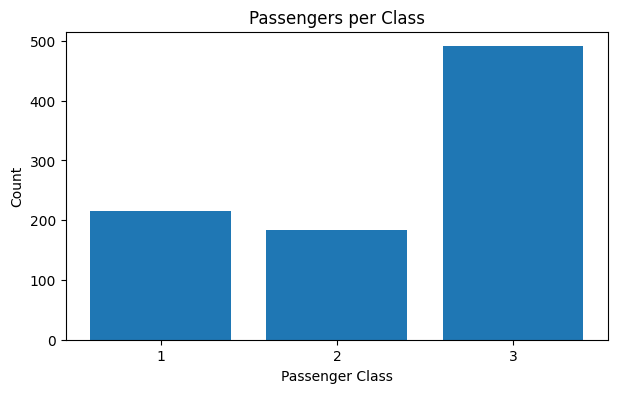

In [97]:
# Bar chart: passengers per class
pclass_counts = df_cleaned["Pclass"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(pclass_counts.index.astype(str), pclass_counts.values)
plt.title("Passengers per Class")
plt.xlabel("Passenger Class")
plt.ylabel("Count")
plt.show()

In [98]:
# Age distribution summary
display(df_cleaned["Age"].describe())

count    891.000000
mean      29.361582
std       13.019697
min        0.420000
25%       22.000000
50%       28.000000
75%       35.000000
max       80.000000
Name: Age, dtype: float64

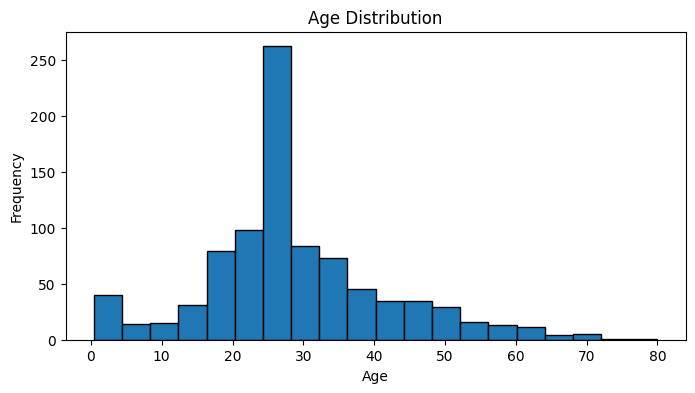

In [99]:
# Histogram: age distribution
plt.figure(figsize=(8, 4))
plt.hist(df_cleaned["Age"], bins=20, edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

In [100]:
# Fare distribution summary
display(df_cleaned["Fare"].describe())

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

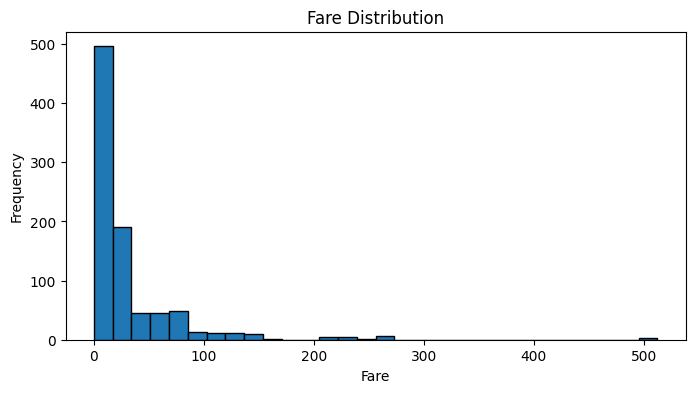

In [101]:
# Histogram: fare distribution
plt.figure(figsize=(8, 4))
plt.hist(df_cleaned["Fare"], bins=30, edgecolor="black")
plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.show()

## 13. Bivariate Analysis


In [102]:
# Survival rate by gender
survival_by_gender = df_prep.groupby("Sex")["Survived"].mean()
display(survival_by_gender)

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

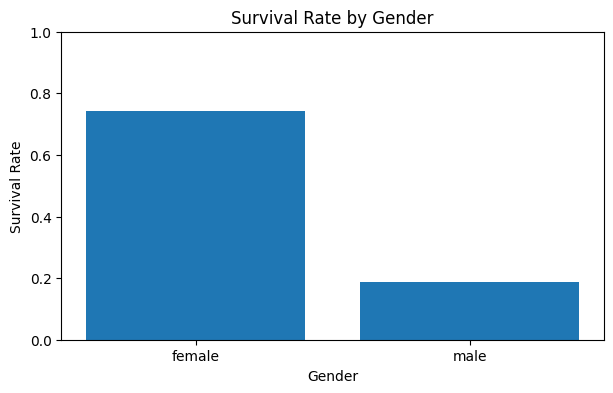

In [103]:
# Bar chart: survival rate by gender
survival_by_gender = df_prep.groupby("Sex")["Survived"].mean()

plt.figure(figsize=(7, 4))
plt.bar(survival_by_gender.index, survival_by_gender.values)
plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.show()

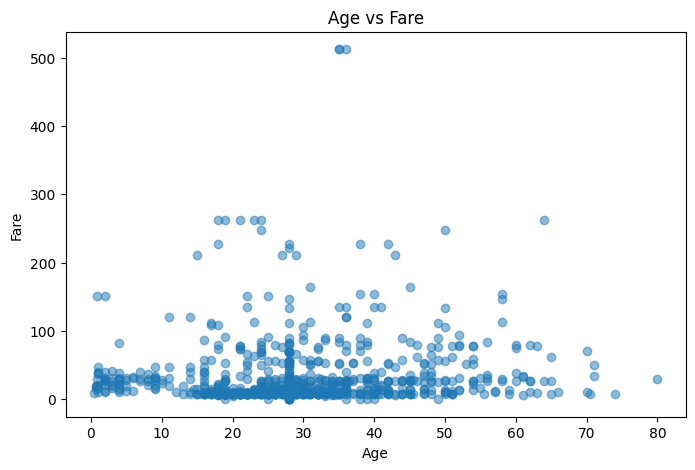

In [104]:
# Scatter plot: Age vs Fare
plt.figure(figsize=(8, 5))
plt.scatter(df_prep["Age"], df_prep["Fare"], alpha=0.5)
plt.title("Age vs Fare")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.show()


### Key Findings from Bivariate Analysis

1. **Gender and Survival:**
   Female passengers had a higher survival rate than male passengers.

2. **Family Size and Survival:**
   Passengers traveling with small families generally had better survival rates than passengers traveling alone.

3. **Embarked and Survival:**
   Survival rates differed between passengers from different embarkation ports.

4. **Age and Fare:**
   Fare values show a wide range, with some passengers paying significantly higher ticket prices.


## 14. Correlation Analysis


In [105]:
# Correlation matrix after feature preparation

correlation_columns = [
    "Survived",
    "Pclass",
    "Age",
    "Fare",
    "SibSp",
    "Parch",
    "Sex_Encoded",
    "Embarked_Encoded",
    "FamilySize",
    "IsAlone"
]

corr_matrix = df_prep[correlation_columns].corr()
display(corr_matrix)

,Survived,Pclass,Age,Fare,SibSp,Parch,Sex_Encoded,Embarked_Encoded,FamilySize,IsAlone
Survived,1.000000,-0.338481,-0.064910,0.257307,-0.035322,0.081629,-0.543351,-0.167675,0.016639,-0.203367
Pclass,-0.338481,1.000000,-0.339898,-0.549500,0.083081,0.018443,0.131900,0.162098,0.065997,0.135207
Age,-0.064910,-0.339898,1.000000,0.096688,-0.233296,-0.172482,0.081163,-0.018754,-0.245619,0.171647
Fare,0.257307,-0.549500,0.096688,1.000000,0.159651,0.216225,-0.182333,-0.224719,0.217138,-0.271832
SibSp,-0.035322,0.083081,-0.233296,0.159651,1.000000,0.414838,-0.114631,0.068230,0.890712,-0.584471
Parch,0.081629,0.018443,-0.172482,0.216225,0.414838,1.000000,-0.245489,0.039798,0.783111,-0.583398
Sex_Encoded,-0.543351,0.131900,0.081163,-0.182333,-0.114631,-0.245489,1.000000,0.108262,-0.200988,0.303646
Embarked_Encoded,-0.167675,0.162098,-0.018754,-0.224719,0.068230,0.039798,0.108262,1.000000,0.066516,0.063532
FamilySize,0.016639,0.065997,-0.245619,0.217138,0.890712,0.783111,-0.200988,0.066516,1.000000,-0.690922
IsAlone,-0.203367,0.135207,0.171647,-0.271832,-0.584471,-0.583398,0.303646,0.063532,-0.690922,1.000000


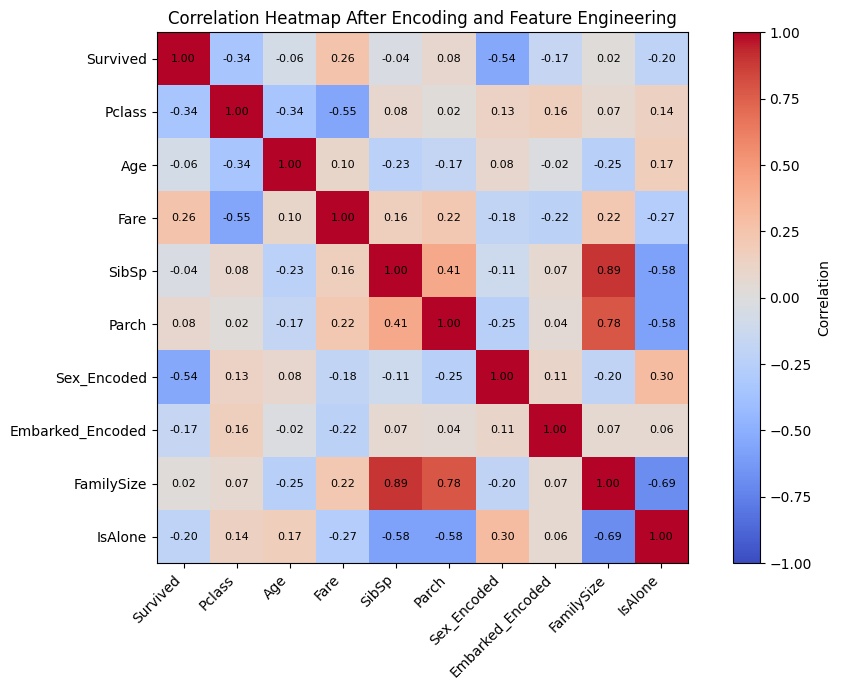

In [106]:
# Correlation heatmap after feature preparation

correlation_columns = [
    "Survived",
    "Pclass",
    "Age",
    "Fare",
    "SibSp",
    "Parch",
    "Sex_Encoded",
    "Embarked_Encoded",
    "FamilySize",
    "IsAlone"
]

corr_matrix = df_prep[correlation_columns].corr()

plt.figure(figsize=(10, 7))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(corr_matrix.index)), corr_matrix.index)

for i in range(len(corr_matrix.index)):
    for j in range(len(corr_matrix.columns)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.title("Correlation Heatmap After Encoding and Feature Engineering")
plt.tight_layout()
plt.show()

## 15. Outlier Detection

In this lecture, we will focus on detecting outliers in the `Fare` column only.

Why `Fare`?

- Ticket prices usually have a wide range.
- Some passengers paid much more than others.
- This makes `Fare` a good example for explaining outliers.

We will detect outliers using three different methods:

1. **IQR method**
2. **Standard Deviation method**
3. **Z-score method**

### 15.1 Explore Fare Before Outlier Detection

Before detecting outliers, we inspect the column with summary statistics and a boxplot.

In [107]:
# Explore Fare before outlier detection

display(df_prep["Fare"].describe())

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

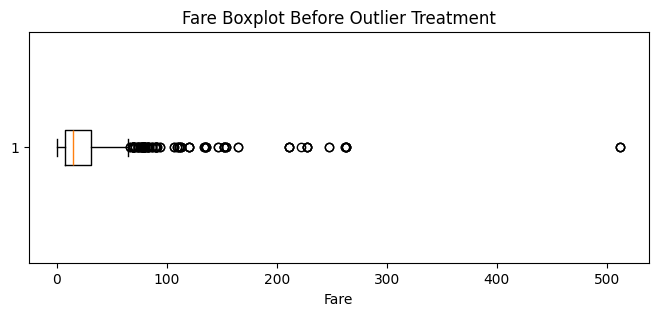

In [108]:
# Boxplot before outlier treatment

plt.figure(figsize=(8, 3))
plt.boxplot(df_prep["Fare"], vert=False)
plt.title("Fare Boxplot Before Outlier Treatment")
plt.xlabel("Fare")
plt.show()

### 15.2 Method 1: IQR Method

IQR means Interquartile Range.

Formula:

`IQR = Q3 - Q1`

Lower bound:

`Q1 - 1.5 * IQR`

Upper bound:

`Q3 + 1.5 * IQR`

Any `Fare` value outside these bounds is considered an outlier by the IQR method.

In [109]:
# Detect Fare outliers using IQR method

Q1_fare = df_prep["Fare"].quantile(0.25)
Q3_fare = df_prep["Fare"].quantile(0.75)
IQR_fare = Q3_fare - Q1_fare

fare_lower_iqr = Q1_fare - 1.5 * IQR_fare
fare_upper_iqr = Q3_fare + 1.5 * IQR_fare

fare_outliers_iqr = df_prep[
    (df_prep["Fare"] < fare_lower_iqr) |
    (df_prep["Fare"] > fare_upper_iqr)
]

print("Q1:", Q1_fare)
print("Q3:", Q3_fare)
print("IQR:", IQR_fare)
print("Lower bound:", fare_lower_iqr)
print("Upper bound:", fare_upper_iqr)
print("Outlier count:", len(fare_outliers_iqr))
print("Outlier percentage:", round(len(fare_outliers_iqr) / len(df_prep) * 100, 2))



Q1: 7.9104
Q3: 31.0
IQR: 23.0896
Lower bound: -26.724
Upper bound: 65.6344
Outlier count: 116
Outlier percentage: 13.02


### 15.3 Method 2: Standard Deviation Method

This method uses the mean and standard deviation.

Common rule:

Lower bound:

`mean - 3 * std`

Upper bound:

`mean + 3 * std`

This method works best when the data is close to a normal distribution.

Because `Fare` is usually skewed, this method may detect fewer outliers than IQR.

In [110]:
# Detect Fare outliers using Mean ± 3 Standard Deviations

fare_mean = df_prep["Fare"].mean()
fare_std = df_prep["Fare"].std()

fare_lower_sd = fare_mean - 3 * fare_std
fare_upper_sd = fare_mean + 3 * fare_std

fare_outliers_sd = df_prep[
    (df_prep["Fare"] < fare_lower_sd) |
    (df_prep["Fare"] > fare_upper_sd)
]

print("Mean:", fare_mean)
print("Standard deviation:", fare_std)
print("Lower bound:", fare_lower_sd)
print("Upper bound:", fare_upper_sd)
print("Outlier count:", len(fare_outliers_sd))
print("Outlier percentage:", round(len(fare_outliers_sd) / len(df_prep) * 100, 2))

display(df.loc[fare_outliers_sd.index, ["PassengerId", "Pclass", "Sex", "Age", "Fare", "Survived"]].head(10))

Mean: 32.204207968574636
Standard deviation: 49.6934285971809
Lower bound: -116.87607782296804
Upper bound: 181.2844937601173
Outlier count: 20
Outlier percentage: 2.24


,PassengerId,Pclass,Sex,Age,Fare,Survived
27,28,1,male,19.0,263.0000,0
88,89,1,female,23.0,263.0000,1
118,119,1,male,24.0,247.5208,0
258,259,1,female,35.0,512.3292,1
299,300,1,female,50.0,247.5208,1
311,312,1,female,18.0,262.3750,1
341,342,1,female,24.0,263.0000,1
377,378,1,male,27.0,211.5000,0
380,381,1,female,42.0,227.5250,1
438,439,1,male,64.0,263.0000,0


### 15.4 Method 3: Z-score Method

Z-score tells us how far a value is from the mean in standard deviation units.

Formula:

`z = (x - mean) / std`

Common rule:

If `abs(z) > 3`, the value is considered an outlier.

The Z-score method and the Standard Deviation method are closely related.

In [111]:
# Detect Fare outliers using Z-score

fare_mean = df_prep["Fare"].mean()
fare_std = df_prep["Fare"].std()

df_prep["Fare_Zscore"] = (df_prep["Fare"] - fare_mean) / fare_std

fare_outliers_zscore = df_prep[df_prep["Fare_Zscore"].abs() > 3]

print("Outlier count:", len(fare_outliers_zscore))
print("Outlier percentage:", round(len(fare_outliers_zscore) / len(df_prep) * 100, 2))
print("Max absolute Z-score:", round(df_prep["Fare_Zscore"].abs().max(), 2))

display(
    fare_outliers_zscore[
        ["Pclass", "Sex", "Age", "Fare", "Fare_Zscore", "Survived"]
    ].head(10)
)

Outlier count: 20
Outlier percentage: 2.24
Max absolute Z-score: 9.66


,Pclass,Sex,Age,Fare,Fare_Zscore,Survived
27,1,male,19.0,263.0000,4.644393,0
88,1,female,23.0,263.0000,4.644393,1
118,1,male,24.0,247.5208,4.332899,0
258,1,female,35.0,512.3292,9.661740,1
299,1,female,50.0,247.5208,4.332899,1
311,1,female,18.0,262.3750,4.631815,1
341,1,female,24.0,263.0000,4.644393,1
377,1,male,27.0,211.5000,3.608038,0
380,1,female,42.0,227.5250,3.930516,1
438,1,male,64.0,263.0000,4.644393,0


### 15.5 Compare the Three Outlier Methods

Now we compare the number of outliers detected by each method.

This helps students understand that different methods can produce different results.

In [112]:
# Compare outlier methods for Fare

fare_outlier_methods = pd.DataFrame({
    "Method": ["IQR", "Mean ± 3SD", "Z-score"],
    "Lower Bound": [fare_lower_iqr, fare_lower_sd, -3],
    "Upper Bound": [fare_upper_iqr, fare_upper_sd, 3],
    "Outlier Count": [
        len(fare_outliers_iqr),
        len(fare_outliers_sd),
        len(fare_outliers_zscore)
    ],
    "Outlier %": [
        round(len(fare_outliers_iqr) / len(df_prep) * 100, 2),
        round(len(fare_outliers_sd) / len(df_prep) * 100, 2),
        round(len(fare_outliers_zscore) / len(df_prep) * 100, 2)
    ]
})

display(fare_outlier_methods)

,Method,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,IQR,-26.724000,65.634400,116,13.02
1,Mean ± 3SD,-116.876078,181.284494,20,2.24
2,Z-score,-3.000000,3.000000,20,2.24


## 16. Fare Outlier Treatment

We will treat `Fare` outliers using **capping** with the IQR bounds.

Why capping?

- It keeps all rows in the dataset.
- It reduces the effect of extreme ticket prices.
- It lets us compare before and after treatment clearly.

We create a treated copy:

`df_outlier_treated`

In [113]:
# Create a treated copy

df_outlier_treated = df_prep.copy()

print("Original shape:", df_prep.shape)
print("Treated copy shape:", df_outlier_treated.shape)

Original shape: (891, 13)
Treated copy shape: (891, 13)


In [114]:
# Cap Fare outliers using IQR bounds

df_outlier_treated["Fare_Capped"] = df_outlier_treated["Fare"].clip(
    lower=fare_lower_iqr,
    upper=fare_upper_iqr
)

print("Original Fare max:", df_outlier_treated["Fare"].max())
print("Capped Fare max:", df_outlier_treated["Fare_Capped"].max())

Original Fare max: 512.3292
Capped Fare max: 65.6344


### 16.1 Fare Before and After Treatment

Now we compare the original `Fare` and the treated `Fare_Capped`.

In [115]:
# Compare Fare before and after treatment

fare_before_after = pd.DataFrame({
    "Before Treatment": df_prep["Fare"].describe(),
    "After Treatment": df_outlier_treated["Fare_Capped"].describe()
})

display(fare_before_after)

,Before Treatment,After Treatment
count,891.000000,891.000000
mean,32.204208,24.046813
std,49.693429,20.481625
min,0.000000,0.000000
25%,7.910400,7.910400
50%,14.454200,14.454200
75%,31.000000,31.000000
max,512.329200,65.634400


In [116]:
# Show sample rows before and after Fare treatment

display(
    df.loc[df_outlier_treated.index, ["PassengerId", "Pclass", "Sex", "Age", "Fare", "Survived"]]
      .assign(Fare_Capped=df_outlier_treated["Fare_Capped"])
      .sort_values("Fare", ascending=False)
      .head(10)
)

,PassengerId,Pclass,Sex,Age,Fare,Survived,Fare_Capped
258,259,1,female,35.0,512.3292,1,65.6344
737,738,1,male,35.0,512.3292,1,65.6344
679,680,1,male,36.0,512.3292,1,65.6344
88,89,1,female,23.0,263.0000,1,65.6344
27,28,1,male,19.0,263.0000,0,65.6344
341,342,1,female,24.0,263.0000,1,65.6344
438,439,1,male,64.0,263.0000,0,65.6344
311,312,1,female,18.0,262.3750,1,65.6344
742,743,1,female,21.0,262.3750,1,65.6344
118,119,1,male,24.0,247.5208,0,65.6344


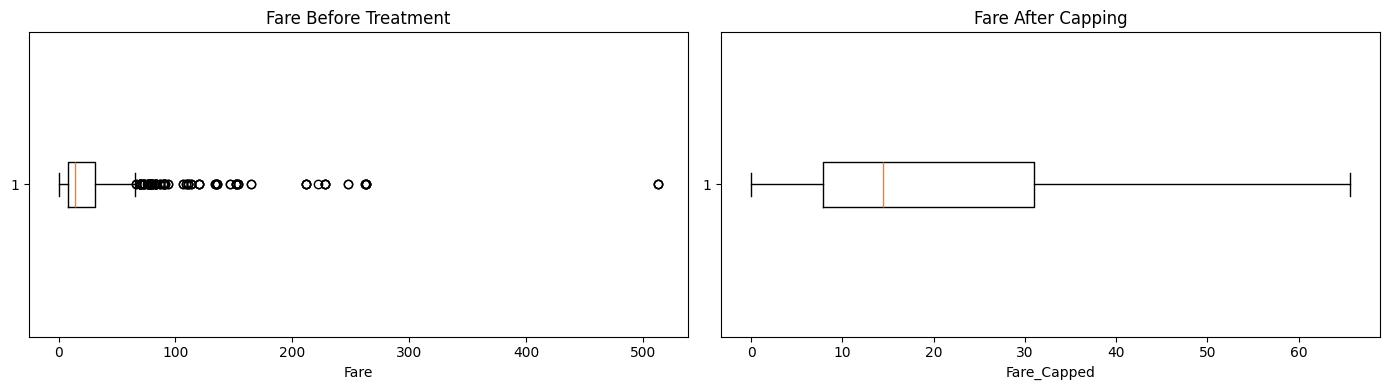

In [117]:
# Boxplot before and after Fare outlier treatment

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].boxplot(df_prep["Fare"], vert=False)
axes[0].set_title("Fare Before Treatment")
axes[0].set_xlabel("Fare")

axes[1].boxplot(df_outlier_treated["Fare_Capped"], vert=False)
axes[1].set_title("Fare After Capping")
axes[1].set_xlabel("Fare_Capped")

plt.tight_layout()
plt.show()

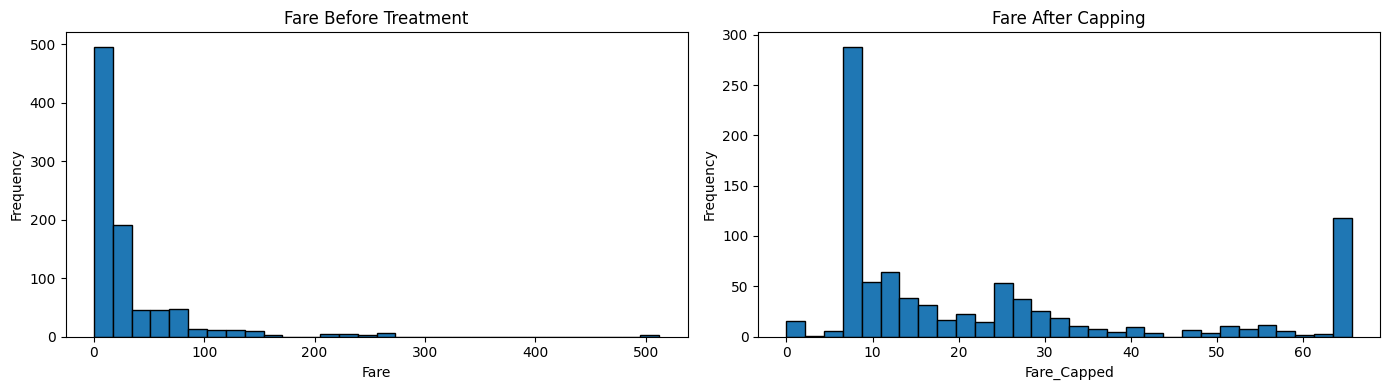

In [118]:
# Histogram before and after Fare treatment

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df_prep["Fare"], bins=30, edgecolor="black")
axes[0].set_title("Fare Before Treatment")
axes[0].set_xlabel("Fare")
axes[0].set_ylabel("Frequency")

axes[1].hist(df_outlier_treated["Fare_Capped"], bins=30, edgecolor="black")
axes[1].set_title("Fare After Capping")
axes[1].set_xlabel("Fare_Capped")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [119]:
# Replace Fare with the treated version for the next steps

df_prep["Fare_Original"] = df_prep["Fare"]
df_prep["Fare"] = df_outlier_treated["Fare_Capped"]

print("Fare column now contains capped values.")
display(df_prep[["Fare_Original", "Fare"]].describe())

Fare column now contains capped values.


,Fare_Original,Fare
count,891.000000,891.000000
mean,32.204208,24.046813
std,49.693429,20.481625
min,0.000000,0.000000
25%,7.910400,7.910400
50%,14.454200,14.454200
75%,31.000000,31.000000
max,512.329200,65.634400


## 17. Scaling Numerical Features

Scaling is useful when columns have very different ranges.

Example:

- `Age` may range from 0 to 80
- `Fare` may range from 0 to hundreds

Some machine learning algorithms work better when numerical features are scaled.


In [120]:
# Standardize Age manually

age_mean = df_prep["Age"].mean()
age_std = df_prep["Age"].std()
df_prep["Age_Standardized"] = (df_prep["Age"] - age_mean) / age_std

display(df_prep[["Age", "Age_Standardized"]].head())

,Age,Age_Standardized
0,22.0,-0.565419
1,38.0,0.663488
2,26.0,-0.258192
3,35.0,0.433068
4,35.0,0.433068


In [121]:
# Normalize Fare manually

fare_min = df_prep["Fare"].min()
fare_max = df_prep["Fare"].max()
df_prep["Fare_Normalized"] = (df_prep["Fare"] - fare_min) / (fare_max - fare_min)

display(df_prep[["Fare", "Fare_Normalized"]].head())

,Fare,Fare_Normalized
0,7.2500,0.110460
1,65.6344,1.000000
2,7.9250,0.120745
3,53.1000,0.809027
4,8.0500,0.122649



## 18. EDA Summary

### 1. Dataset Overview
- The dataset contains 891 rows and 12 columns.
- It includes numerical and categorical features.

### 2. Missing Values
- Cabin: 687 missing values (77.10%).
- Age: 177 missing values (19.87%).
- Embarked: 2 missing values (0.22%).

### 3. Data Cleaning
- Dropped Cabin due to a high percentage of missing values.
- Filled Age using the median.
- Filled Embarked using the mode.
- No duplicate rows were found.

### 4. Feature Engineering
- Created Sex_Encoded and Embarked_Encoded.
- Created FamilySize and IsAlone.

### 5. Important Findings
- Overall survival rate was approximately 38.38%.
- Female passengers had a higher survival rate (74.20%) than male passengers (18.89%).
- Passengers traveling alone had a lower survival rate than those traveling with family.

### 6. Outlier Detection
- Applied IQR, Standard Deviation, and Z-score methods.
- IQR detected 116 outliers in Fare.
- Capped extreme Fare values using IQR bounds.

### 7. Feature Scaling
- Applied Standardization to Age.
- Applied Normalization to Fare.

### Conclusion

EDA helped us understand the dataset, identify data quality issues, discover patterns, and prepare features for future machine learning tasks.
